FICHIER jupiter  Analyse des donnees.ipynb


2) Affichage des données 

2) Affichage des donnees

Roulement sans Défauts charge moteur hp=1

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# ==========================================
# 1. CHARGEMENT DES DONNÉES
# ==========================================
# Charger le fichier MAT téléchargé

#Reférence roulements "Sains"
chemin_97 = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\Sains\97.mat"
mat_data_97 = loadmat(chemin_97)

#Référence roulements "Défauts"
chemin_109 = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\Defauts\109.mat"
mat_data_109 = loadmat(chemin_109)
chemin_110 = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\Defauts\110.mat"
mat_data_110 = loadmat(chemin_110)
chemin_111 = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\Defauts\111.mat"
mat_data_111 = loadmat(chemin_111)
chemin_112 = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\Defauts\112.mat"
mat_data_112 = loadmat(chemin_112)
chemin_176 = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\Defauts\176.mat"
mat_data_176 = loadmat(chemin_176)
chemin_215 = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\Defauts\215.mat"
mat_data_215 = loadmat(chemin_215)


Nombre de points de mesure : 243938
Durée du signal analysé : 20.33 secondes


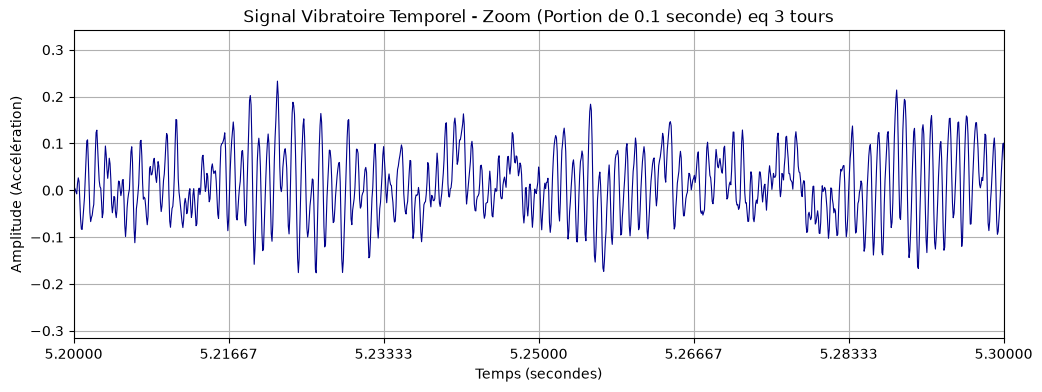

In [24]:
# Extraire le signal vibratoire (ajuster le nom de la clé si nécessaire)
# Dans votre fichier, la variable s'appelle 'X098_DE_time'
signal = mat_data_97['X097_DE_time'].ravel()


# ==========================================
# 2. CONFIGURATION DES PARAMÈTRES DU SIGNAL
# ==========================================
# Fréquence d'échantillonnage théorique (en Hz)
# Note : 12000 Hz est la valeur standard pour les données CWRU (Drive End data)
fs = 12000  

# Nombre de points dans le signal
N = len(signal)

# Durée totale du signal en secondes
duree = N / fs

print(f"Nombre de points de mesure : {N}")
print(f"Durée du signal analysé : {duree:.2f} secondes")# 3. Création du vecteur temps (en secondes)
# Chaque point de mesure correspond à un instant précis : t = indice / fs
temps = np.arange(N) / fs


# ========================================================
# INSTRUCTION POUR ZOOMER SUR UNE COURTE PORTION (0.1 à 0.3s)
# C'est cette vue qui permet d'analyser la forme des chocs
# ========================================================
plt.figure(figsize=(12, 4))
plt.plot(temps, signal, color='darkblue', linewidth=0.8)
plt.title("Signal Vibratoire Temporel - Zoom (Portion de 0.1 seconde) eq 3 tours")
plt.xlabel("Temps (secondes)")
plt.ylabel("Amplitude (Accélération)")

# On limite l'affichage entre 5.2 et 5.3 secondes pour voir le détail
plt.xlim(5.2, 5.3) 

# Définition des bornes min et max du graphique
t_min, t_max = 5.2, 5.3
# Génération de 6 valeurs parfaitement réparties
graduations_1 = np.linspace(t_min, t_max, 7)
# Application des graduations sur l'axe X
plt.xticks(graduations_1)

plt.grid(True)
plt.show()

AFFICHAGE BOXPLOT   & COURBES DE GAUSSE 


Roulement sans Défauts charge moteur hp=1

<>:46: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:46: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:55: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:59: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:46: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:46: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:55: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences wil

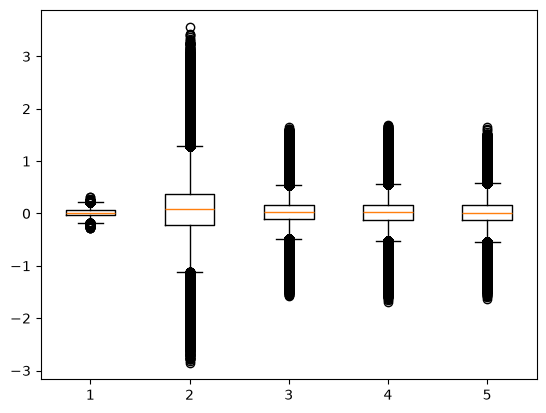

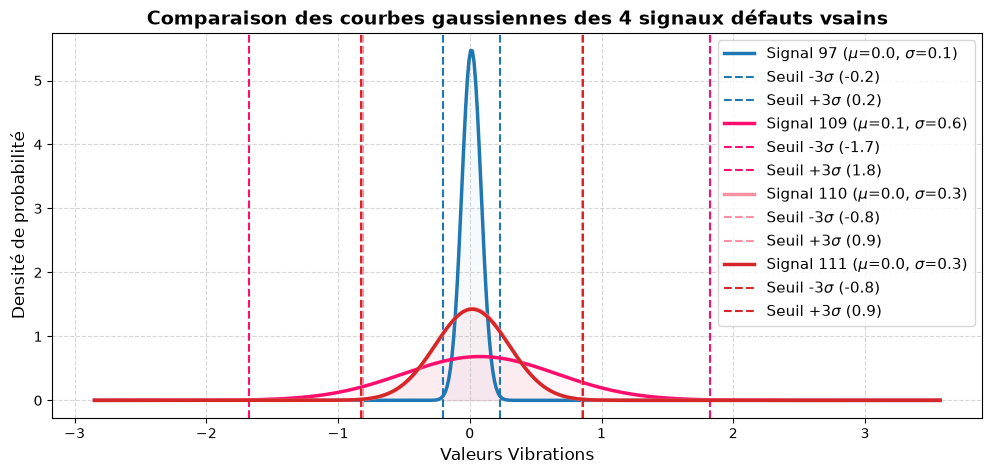

In [25]:
import matplotlib.pyplot as plt
import scipy.stats as stats

# Extraire le signal vibratoire (ajuster le nom de la clé si nécessaire)
# Dans votre fichier, la variable s'appelle 'X098_DE_time'

signal_97 = mat_data_97['X097_DE_time'].ravel()

signal_109 = mat_data_109['X109_DE_time'].ravel()
signal_110 = mat_data_110['X110_DE_time'].ravel()
signal_111 = mat_data_111['X111_DE_time'].ravel()
signal_112 = mat_data_112['X112_DE_time'].ravel()

plt.boxplot([signal_97, signal_109, signal_110, signal_111, signal_112], label=['Sains_97', '109', '110', '111', '112']);


# Regroupement des signaux dans un dictionnaire pour automatiser le tracé
signaux = {
    'Signal 97': signal_97,
    'Signal 109': signal_109,
    'Signal 110': signal_110,
    'Signal 111': signal_111,
    'Signal 112': signal_112
}

# 2. Configuration de la figure
plt.figure(figsize=(12, 5))

# Définition d'un axe X global couvrant l'ensemble des données
toutes_valeurs = np.concatenate([signal_97, signal_109, signal_110, signal_111, signal_112])
x = np.linspace(min(toutes_valeurs), max(toutes_valeurs), 500)

# Couleurs personnalisées pour chaque courbe
couleurs = ['#1f77b4', "#ff0e6e", "#f891a3", '#d62728']

# 3. Calcul et tracé de la courbe gaussienne pour chaque série
for (nom, donnees), couleur in zip(signaux.items(), couleurs):
    # Calcul de la moyenne (mu) et de l'écart-type (sigma)
    mu = np.mean(donnees)
    sigma = np.std(donnees)
    
    # Génération de la courbe de densité de probabilité (PDF)
    y = stats.norm.pdf(x, mu, sigma)
    
    # Tracé de la ligne de la cloche de Gauss
    plt.plot(x, y, label=f'{nom} ($\mu$={mu:.1f}, $\sigma$={sigma:.1f})', linewidth=2.5, color=couleur)
    
    # Optionnel : Remplissage léger sous la courbe pour améliorer le visuel
    plt.fill_between(x, y, alpha=0.03, color=couleur)
    
    # AJOUT DE LA LIGNE VERTICALE À MOYENNE - 3 SIGMA :
    # Calcul du seuil à -3 sigma
    seuil_inf = mu - 3 * sigma
    plt.axvline(x=seuil_inf, color=couleur, linestyle='--', linewidth=1.5, 
                label=f'Seuil -3$\sigma$ ({seuil_inf:.1f})')
    # Calcul du seuil à +3 sigma
    seuil_sup = mu + 3 * sigma
    plt.axvline(x=seuil_sup, color=couleur, linestyle='--', linewidth=1.5, 
                label=f'Seuil +3$\sigma$ ({seuil_sup:.1f})')


# 4. Habillage du graphique
plt.title("Comparaison des courbes gaussiennes des 4 signaux défauts vsains", fontsize=14, fontweight='bold')
plt.xlabel("Valeurs Vibrations", fontsize=12)
plt.ylabel("Densité de probabilité", fontsize=12)
plt.legend(fontsize=11, loc='upper right')
plt.grid(axis='both', linestyle='--', alpha=0.5)

# 5. Affichage du graphique
plt.show();


AFFICHAGE BOXPLOT   & COURBES DE GAUSSE 


Roulement avec Défauts charge moteur hp=2
Dégfauts  Bague Intérieur 007"


<>:46: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:46: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:55: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:59: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:46: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:46: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:55: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences wil

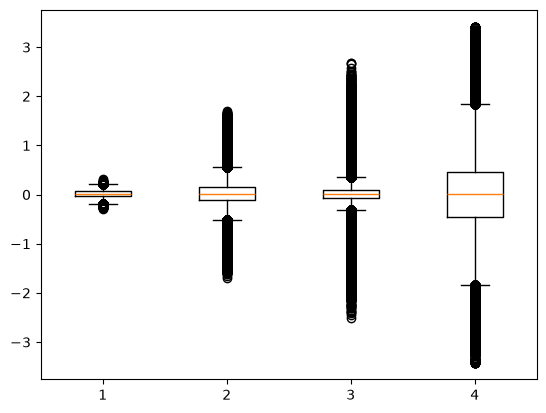

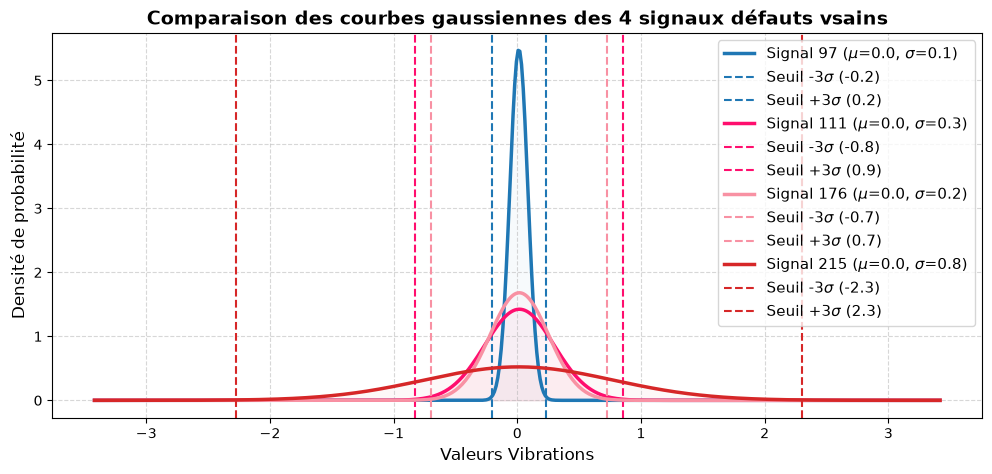

In [26]:
import matplotlib.pyplot as plt
import scipy.stats as stats

# Extraire le signal vibratoire (ajuster le nom de la clé si nécessaire)
# Dans votre fichier, la variable s'appelle 'X098_DE_time'

signal_97 = mat_data_97['X097_DE_time'].ravel()


signal_111 = mat_data_111['X111_DE_time'].ravel()
signal_176 = mat_data_176['X176_DE_time'].ravel()
signal_215 = mat_data_215['X215_DE_time'].ravel()


plt.boxplot([signal_97, signal_111, signal_176, signal_215], label=['Sains_97', '111', '176', '215']);


# Regroupement des signaux dans un dictionnaire pour automatiser le tracé
signaux = {
    'Signal 97': signal_97,
    'Signal 111': signal_111,
    'Signal 176': signal_176,
    'Signal 215': signal_215
}

# 2. Configuration de la figure
plt.figure(figsize=(12, 5))

# Définition d'un axe X global couvrant l'ensemble des données
toutes_valeurs = np.concatenate([signal_97, signal_111, signal_176, signal_215])
x = np.linspace(min(toutes_valeurs), max(toutes_valeurs), 500)

# Couleurs personnalisées pour chaque courbe
couleurs = ['#1f77b4', "#ff0e6e", "#f891a3", '#d62728']

# 3. Calcul et tracé de la courbe gaussienne pour chaque série
for (nom, donnees), couleur in zip(signaux.items(), couleurs):
    # Calcul de la moyenne (mu) et de l'écart-type (sigma)
    mu = np.mean(donnees)
    sigma = np.std(donnees)
    
    # Génération de la courbe de densité de probabilité (PDF)
    y = stats.norm.pdf(x, mu, sigma)
    
    # Tracé de la ligne de la cloche de Gauss
    plt.plot(x, y, label=f'{nom} ($\mu$={mu:.1f}, $\sigma$={sigma:.1f})', linewidth=2.5, color=couleur)
    
    # Optionnel : Remplissage léger sous la courbe pour améliorer le visuel
    plt.fill_between(x, y, alpha=0.03, color=couleur)
    
    # AJOUT DE LA LIGNE VERTICALE À MOYENNE - 3 SIGMA :
    # Calcul du seuil à -3 sigma
    seuil_inf = mu - 3 * sigma
    plt.axvline(x=seuil_inf, color=couleur, linestyle='--', linewidth=1.5, 
                label=f'Seuil -3$\sigma$ ({seuil_inf:.1f})')
    # Calcul du seuil à +3 sigma
    seuil_sup = mu + 3 * sigma
    plt.axvline(x=seuil_sup, color=couleur, linestyle='--', linewidth=1.5, 
                label=f'Seuil +3$\sigma$ ({seuil_sup:.1f})')


# 4. Habillage du graphique
plt.title("Comparaison des courbes gaussiennes des 4 signaux défauts vsains", fontsize=14, fontweight='bold')
plt.xlabel("Valeurs Vibrations", fontsize=12)
plt.ylabel("Densité de probabilité", fontsize=12)
plt.legend(fontsize=11, loc='upper right')
plt.grid(axis='both', linestyle='--', alpha=0.5)

# 5. Affichage du graphique
plt.show();


SUITE A RETRAITER 

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import kurtosis

chemin = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\98.mat"
mat = loadmat(chemin)

de = mat["X098_DE_time"].ravel()      # accéléromètre côté entraînement
fe = mat["X098_FE_time"].ravel()      # accéléromètre côté ventilateur
rpm = float(np.squeeze(mat.get("X098RPM", 1772)))
fr = rpm / 60                         # fréquence de rotation de l'arbre (Hz)

fs = 48000                            # à vérifier, voir la remarque plus bas
t = np.arange(len(de)) / fs
print(f"{len(de)} échantillons, durée = {len(de)/fs:.2f} s, fr = {fr:.2f} Hz")

# Indicateurs statistiques
def indicateurs(x, nom):
    rms = np.sqrt(np.mean(x**2))
    print(f"{nom}: moyenne={x.mean():.4f}  RMS={rms:.4f}  "
          f"crête={np.abs(x).max():.3f}  facteur de crête={np.abs(x).max()/rms:.2f}  "
          f"kurtosis={kurtosis(x, fisher=False):.2f}")
indicateurs(de, "DE")
indicateurs(fe, "FE")

# Spectre (FFT avec fenêtre de Hann)
def spectre(x, fs):
    x = x - x.mean()
    w = np.hanning(len(x))
    X = np.abs(np.fft.rfft(x * w)) * 2 / w.sum()
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return f, X

f, X = spectre(de, fs)

# Fréquences caractéristiques du roulement côté entraînement (SKF 6205-2RS)
car = {"BPFO": 3.5848, "BPFI": 5.4152, "BSF": 4.7135, "FTF": 0.39828}

fig, ax = plt.subplots(2, 2, figsize=(14, 8))

n = int(0.2 * fs)  # 0,2 s de signal
ax[0, 0].plot(t[:n], de[:n]); ax[0, 0].set_title("Signal DE (0,2 s)")
ax[0, 1].plot(t[:n], fe[:n], color="tab:orange"); ax[0, 1].set_title("Signal FE (0,2 s)")
for a in ax[0]:
    a.set_xlabel("Temps (s)"); a.set_ylabel("Accélération (g)")

ax[1, 0].hist(de, bins=100, density=True)
ax[1, 0].set_title("Histogramme DE"); ax[1, 0].set_xlabel("Amplitude")

ax[1, 1].semilogy(f, X)
ax[1, 1].axvline(fr, color="r", ls="--", label=f"1×fr = {fr:.1f} Hz")
for nom, k in car.items():
    ax[1, 1].axvline(k * fr, color="g", ls=":", alpha=0.7)
    ax[1, 1].text(k * fr, X.max(), nom, rotation=90, va="top", fontsize=8)
ax[1, 1].set_xlim(0, 1000)
ax[1, 1].set_title("Spectre DE (0-1000 Hz)")
ax[1, 1].set_xlabel("Fréquence (Hz)"); ax[1, 1].set_ylabel("Amplitude"); ax[1, 1].legend()

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\ReMarkt\\Documents\\0_PROJET_SCIENTIST\\Data_CWRU\\98.mat'

Roulement DEFAILLANT " 110

dict_keys(['__header__', '__version__', '__globals__', 'X110_DE_time', 'X110_FE_time', 'X110RPM'])
                 DE        FE
temps (s)                    
0.000000   0.032127  0.086291
0.000021   0.078231  0.110535
0.000042   0.161468  0.110124
0.000063   0.250547  0.080127
0.000083   0.315426  0.004725
0.000104   0.311463 -0.011711
0.000125   0.233023 -0.013149
0.000146   0.115782  0.004931
0.000167  -0.011265  0.014793
0.000188  -0.112861  0.012944
                 DE        FE
temps (s)                    
10.129563 -0.121623  0.195798
10.129583 -0.128507  0.312907
10.129604 -0.088453  0.401458
10.129625 -0.028998  0.467820
10.129646  0.008553  0.525347
                  DE             FE
count  486224.000000  486224.000000
mean        0.020731       0.030707
std         0.277919       0.231544
min        -1.574212      -1.163489
25%        -0.105977      -0.120396
50%         0.022113       0.033900
75%         0.153332       0.185731
max         1.651608       0.943036
(486224

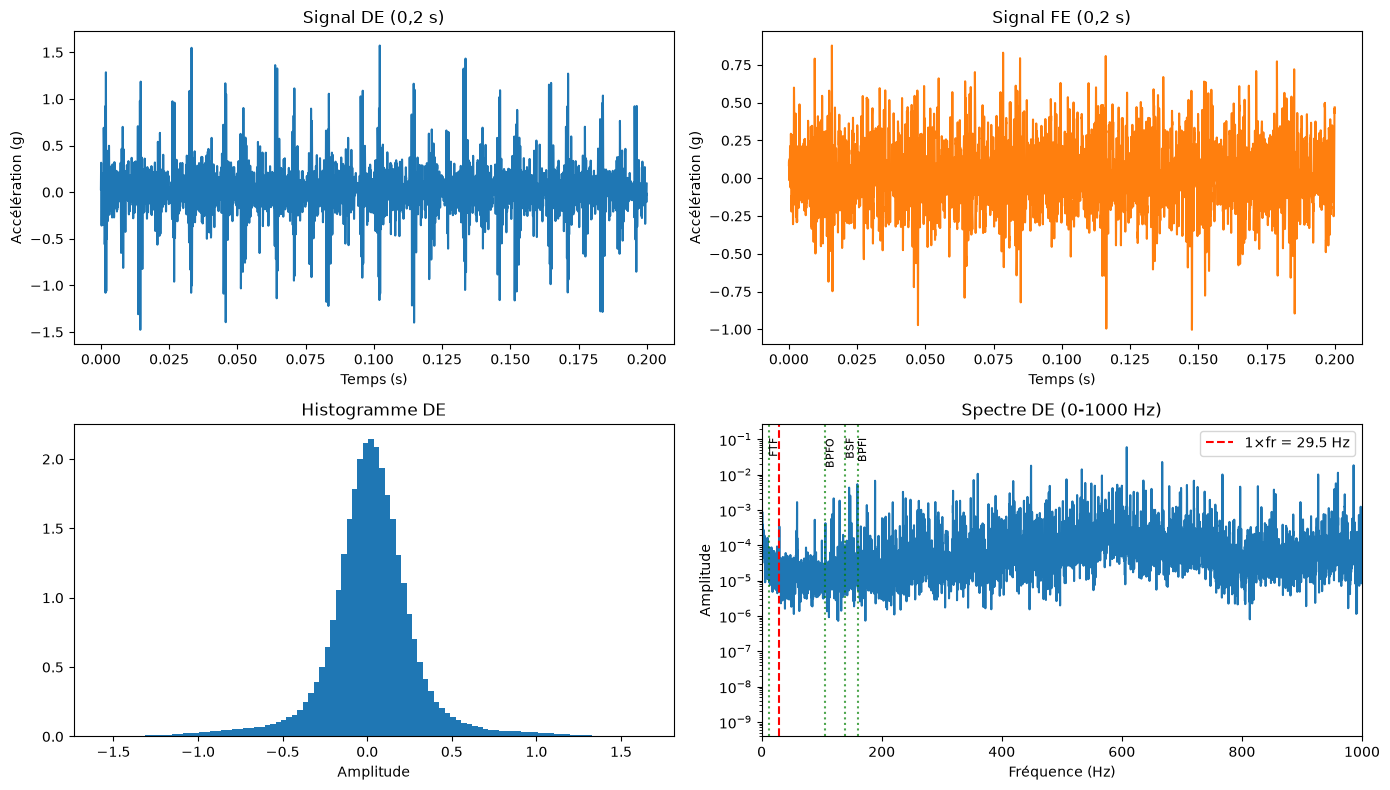

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import kurtosis

chemin = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\110.mat"
mat = loadmat(chemin)

print(mat.keys())  # Affiche les clés du dictionnaire chargé depuis le fichier .mat


# Extrait le signal temporel de l'accéléromètre placé du côté entraînement (Drive End). 
# La fonction .ravel() l'aplatit pour obtenir un tableau à une seule dimension
de = mat["X110_DE_time"].ravel()      # accéléromètre côté entraînement

# Extrait le signal de l'accéléromètre placé du côté ventilateur (Fan End).
fe = mat["X110_FE_time"].ravel()      # accéléromètre côté ventilateur

fs = 48000                            # fréquence d'échantillonnage (Hz)

df = pd.DataFrame({
    'DE': mat['X110_DE_time'].ravel(),
    'FE': mat['X110_FE_time'].ravel()
    #'RPM': mat['X110RPM'].ravel(),  
})

df.index = df.index / fs
df.index.name = 'temps (s)'

# Supprime la limite d'affichage des lignes pour describe
pd.set_option('display.max_rows', None)

print(df.head(10))      # 10 premières lignes
print(df.tail(5))       # 5 dernières lignes
print(df.describe())# count, mean, std, min, quartiles, max
print(df.shape)         # (486224, 3)






rpm = float(np.squeeze(mat.get("X110RPM", 1772)))
fr = rpm / 60                         # fréquence de rotation de l'arbre (Hz)

fs = 48000                            # à vérifier, voir la remarque plus bas
t = np.arange(len(de)) / fs
print(f"{len(de)} échantillons, durée = {len(de)/fs:.2f} s, fr = {fr:.2f} Hz")

# Indicateurs statistiques
def indicateurs(x, nom):
    rms = np.sqrt(np.mean(x**2))
    print(f"{nom}: moyenne={x.mean():.4f}  RMS={rms:.4f}  "
          f"crête={np.abs(x).max():.3f}  facteur de crête={np.abs(x).max()/rms:.2f}  "
          f"kurtosis={kurtosis(x, fisher=False):.2f}")
indicateurs(de, "DE")
indicateurs(fe, "FE")

# Spectre (FFT avec fenêtre de Hann)
def spectre(x, fs):
    x = x - x.mean()
    w = np.hanning(len(x))
    X = np.abs(np.fft.rfft(x * w)) * 2 / w.sum()
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return f, X

f, X = spectre(de, fs)

# Fréquences caractéristiques du roulement côté entraînement (SKF 6205-2RS)
car = {"BPFO": 3.5848, "BPFI": 5.4152, "BSF": 4.7135, "FTF": 0.39828}

fig, ax = plt.subplots(2, 2, figsize=(14, 8))

n = int(0.2 * fs)  # 0,2 s de signal
ax[0, 0].plot(t[:n], de[:n]); ax[0, 0].set_title("Signal DE (0,2 s)")
ax[0, 1].plot(t[:n], fe[:n], color="tab:orange"); ax[0, 1].set_title("Signal FE (0,2 s)")
for a in ax[0]:
    a.set_xlabel("Temps (s)"); a.set_ylabel("Accélération (g)")

ax[1, 0].hist(de, bins=100, density=True)
ax[1, 0].set_title("Histogramme DE"); ax[1, 0].set_xlabel("Amplitude")

ax[1, 1].semilogy(f, X)
ax[1, 1].axvline(fr, color="r", ls="--", label=f"1×fr = {fr:.1f} Hz")
for nom, k in car.items():
    ax[1, 1].axvline(k * fr, color="g", ls=":", alpha=0.7)
    ax[1, 1].text(k * fr, X.max(), nom, rotation=90, va="top", fontsize=8)
ax[1, 1].set_xlim(0, 1000)
ax[1, 1].set_title("Spectre DE (0-1000 Hz)")
ax[1, 1].set_xlabel("Fréquence (Hz)"); ax[1, 1].set_ylabel("Amplitude"); ax[1, 1].legend()

plt.tight_layout()
plt.show()